# Held-out evaluation and business interpretation

Executed against the uploaded real dataset and its verified analysis artifacts. Outputs below were captured from the code cells.

In [1]:
from pathlib import Path
import sys, subprocess, json
import pandas as pd
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/schema.py').exists())
sys.path.insert(0, str(ROOT))
def run_stage(name):
    completed = subprocess.run([sys.executable, str(ROOT / 'scripts' / name)], cwd=ROOT, capture_output=True, text=True)
    print(completed.stdout)
    if completed.stderr:
        print(completed.stderr)
    completed.check_returncode()
print('Project directory:', ROOT.name)


Project directory: flight_disruption_project


Read the frozen holdout results. Do not use this notebook to select parameters or thresholds from test labels.

In [2]:
result = json.loads((ROOT / 'reports/test_metrics.json').read_text())
print(json.dumps(result, indent=2))
display(pd.read_csv(ROOT / 'reports/validation_subgroup_metrics.csv'))
display(pd.read_csv(ROOT / 'reports/test_subgroup_metrics.csv'))
display(pd.read_csv(ROOT / 'reports/test_cost_sensitivity.csv'))

{
  "status": "TRAINED_REAL_DATA",
  "selected_model": "hist_gradient_boosting",
  "selected": {
    "n": 947202,
    "prevalence": 0.19263156116646712,
    "average_precision": 0.2663304744222081,
    "roc_auc": 0.6170949154942871,
    "brier_score": 0.15257185805524776,
    "log_loss": 0.4794651275488444,
    "threshold": 0.32787811995956606,
    "alert_rate": 0.12187157544008564,
    "precision": 0.302173479906789,
    "recall": 0.19117510043242117,
    "f1": 0.23418754070185097,
    "tn": 684186,
    "fp": 80555,
    "fn": 147579,
    "tp": 34882,
    "rank_budget": 0.1,
    "precision_at_budget": 0.3089210304054054,
    "recall_at_budget": 0.1603685171077655,
    "lift_at_budget": 1.6036885572372224,
    "scenario_cost_per_1000": 864.0712329577007,
    "day_cluster_bootstrap_95_percent_intervals": {
      "precision": {
        "lower": 0.2697640346721743,
        "upper": 0.33643150071364614
      },
      "recall": {
        "lower": 0.1701369354758561,
        "upper": 0.209520

,group_field,group,n,prevalence,average_precision,roc_auc,brier_score,log_loss,threshold,alert_rate,precision,recall,f1,tn,fp,fn,tp,rank_budget,precision_at_budget,recall_at_budget,lift_at_budget,scenario_cost_per_1000
0,month,9,464946,0.135186,0.201744,0.639713,0.120518,0.401826,0.327878,0.123746,0.229947,0.210488,0.219788,357787,44305,49624,13230,0.1,0.234181,0.173227,1.732291,628.944006
1,month,10,458375,0.128103,0.163327,0.598401,0.115574,0.390859,0.327878,0.075914,0.162715,0.096425,0.121092,370521,29135,53057,5662,0.1,0.174073,0.135884,1.358859,642.312517
2,airport_id_format,IATA_OR_MISSING,464946,0.135186,0.201744,0.639713,0.120518,0.401826,0.327878,0.123746,0.229947,0.210488,0.219788,357787,44305,49624,13230,0.1,0.234181,0.173227,1.732291,628.944006
3,airport_id_format,BTS_ID,458375,0.128103,0.163327,0.598401,0.115574,0.390859,0.327878,0.075914,0.162715,0.096425,0.121092,370521,29135,53057,5662,0.1,0.174073,0.135884,1.358859,642.312517


,group_field,group,n,prevalence,average_precision,roc_auc,brier_score,log_loss,threshold,alert_rate,precision,recall,f1,tn,fp,fn,tp,rank_budget,precision_at_budget,recall_at_budget,lift_at_budget,scenario_cost_per_1000
0,airline,AA,150433,0.185757,0.233912,0.590377,0.150405,0.475971,0.327878,0.075549,0.264936,0.107751,0.153196,114135,8354,24933,3011,0.1,0.262115,0.141104,1.411064,884.240825
1,airline,DL,142867,0.134587,0.177403,0.582971,0.116634,0.394382,0.327878,0.016764,0.236326,0.029436,0.052352,121810,1829,18662,566,0.1,0.216296,0.160703,1.607110,665.927051
2,airline,B6,45040,0.236856,0.336354,0.649060,0.172319,0.522242,0.327878,0.218361,0.351398,0.323960,0.337121,27993,6379,7212,3456,0.1,0.375000,0.158324,1.583240,942.251332
3,airline,UA,86090,0.190893,0.247223,0.594780,0.155455,0.487683,0.327878,0.178290,0.268487,0.250761,0.259321,58428,11228,12313,4121,0.1,0.285515,0.149568,1.495680,845.545360
4,airline,WN,211521,0.203285,0.292896,0.647448,0.156490,0.485479,0.327878,0.212400,0.307989,0.321798,0.314742,137432,31090,29162,13837,0.1,0.333160,0.163888,1.638883,836.323580
5,airline,EV,86712,0.209890,0.284006,0.593443,0.162887,0.505689,0.327878,0.097241,0.352941,0.163516,0.223491,63056,5456,15224,2976,0.1,0.352439,0.167912,1.679160,940.769444
6,airline,OO,94882,0.230065,0.267746,0.568806,0.177998,0.543976,0.327878,0.037668,0.294908,0.048284,0.082982,70533,2520,20775,1054,0.1,0.288364,0.125338,1.253405,1121.340191
7,airline,MQ,41298,0.188895,0.207101,0.529219,0.158163,0.496956,0.327878,0.108649,0.219746,0.126394,0.160482,29996,3501,6815,986,0.1,0.223056,0.118062,1.180847,909.874570
8,airline,HA,12284,0.065532,0.106842,0.658188,0.064736,0.257082,0.327878,0.000000,0.000000,0.000000,0.000000,11479,0,805,0,0.1,0.127850,0.195031,1.950946,327.661999
9,airline,F9,15883,0.255053,0.308977,0.573242,0.190416,0.567586,0.327878,0.317383,0.303313,0.377438,0.336340,8320,3512,2522,1529,0.1,0.341310,0.133794,1.338194,1015.047535


,n,prevalence,average_precision,roc_auc,brier_score,log_loss,threshold,alert_rate,precision,recall,f1,tn,fp,fn,tp,rank_budget,precision_at_budget,recall_at_budget,lift_at_budget,scenario_cost_per_1000,fn_to_fp_cost_ratio
0,947202,0.192632,0.26633,0.617095,0.152572,0.479465,0.327878,0.121872,0.302173,0.191175,0.234188,684186,80555,147579,34882,0.1,0.308921,0.160369,1.603689,240.850421,1
1,947202,0.192632,0.26633,0.617095,0.152572,0.479465,0.327878,0.121872,0.302173,0.191175,0.234188,684186,80555,147579,34882,0.1,0.308921,0.160369,1.603689,396.655624,2
2,947202,0.192632,0.26633,0.617095,0.152572,0.479465,0.327878,0.121872,0.302173,0.191175,0.234188,684186,80555,147579,34882,0.1,0.308921,0.160369,1.603689,864.071233,5
3,947202,0.192632,0.26633,0.617095,0.152572,0.479465,0.327878,0.121872,0.302173,0.191175,0.234188,684186,80555,147579,34882,0.1,0.308921,0.160369,1.603689,1643.097249,10
4,947202,0.192632,0.26633,0.617095,0.152572,0.479465,0.327878,0.121872,0.302173,0.191175,0.234188,684186,80555,147579,34882,0.1,0.308921,0.160369,1.603689,3201.149280,20


November–December holdout, after model and threshold freezing. Average precision is reported separately; it is not trapezoidal PR area.
Read alongside precision–recall and the observed class prevalence.
Threshold chosen from validation scores to respect the validation workload budget; test workload can differ.
Quantile-bin calibration diagnostic; few unique scores may produce fewer than ten points. No claim of calibrated probabilities is assumed.
Validation sample, three repeats. Correlated features may share importance. This is a global predictive association, not a causal or flight-specific explanation.


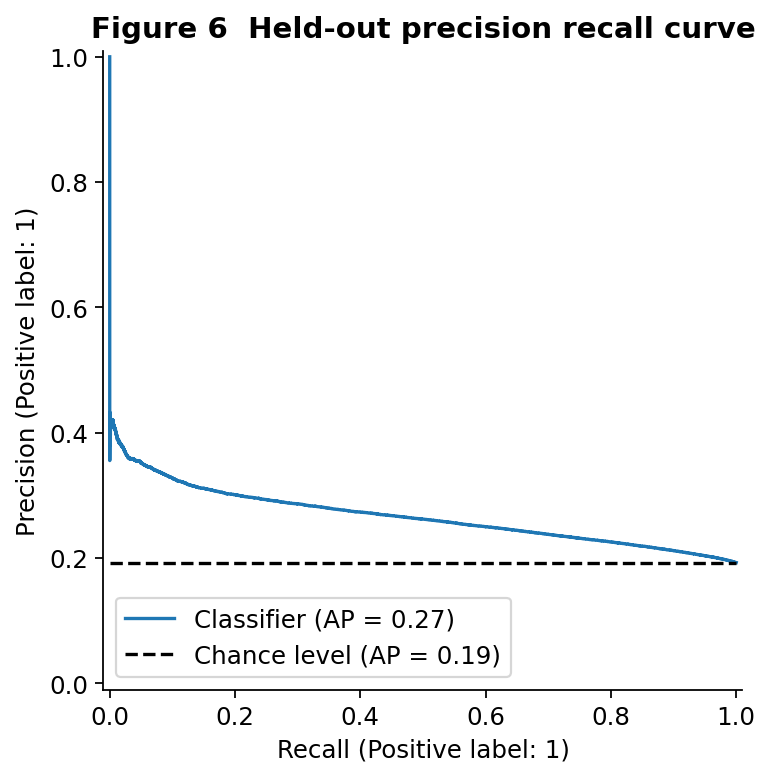

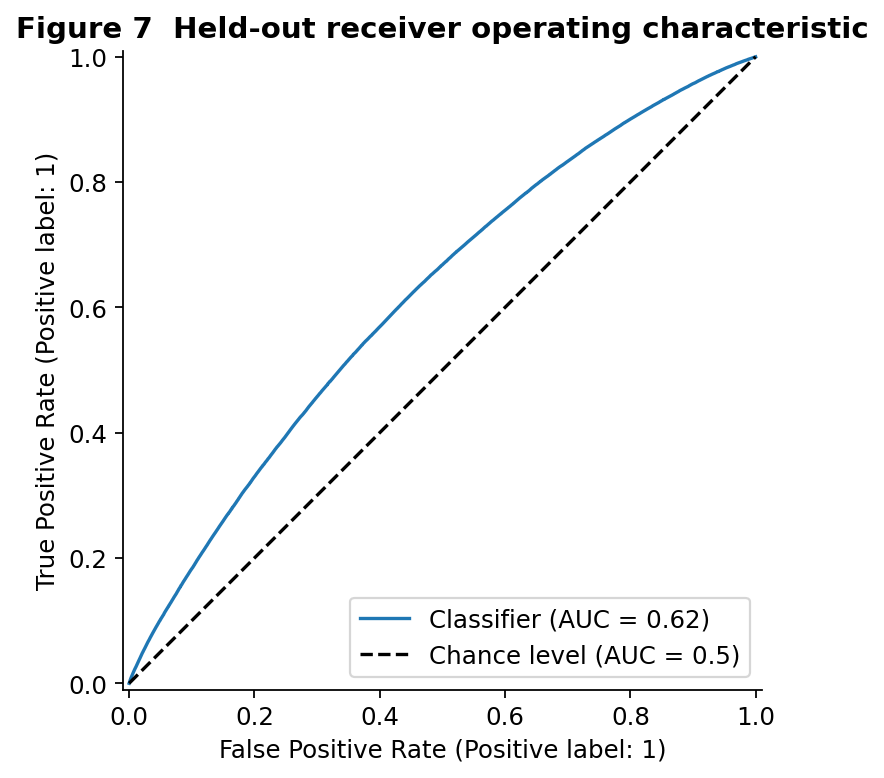

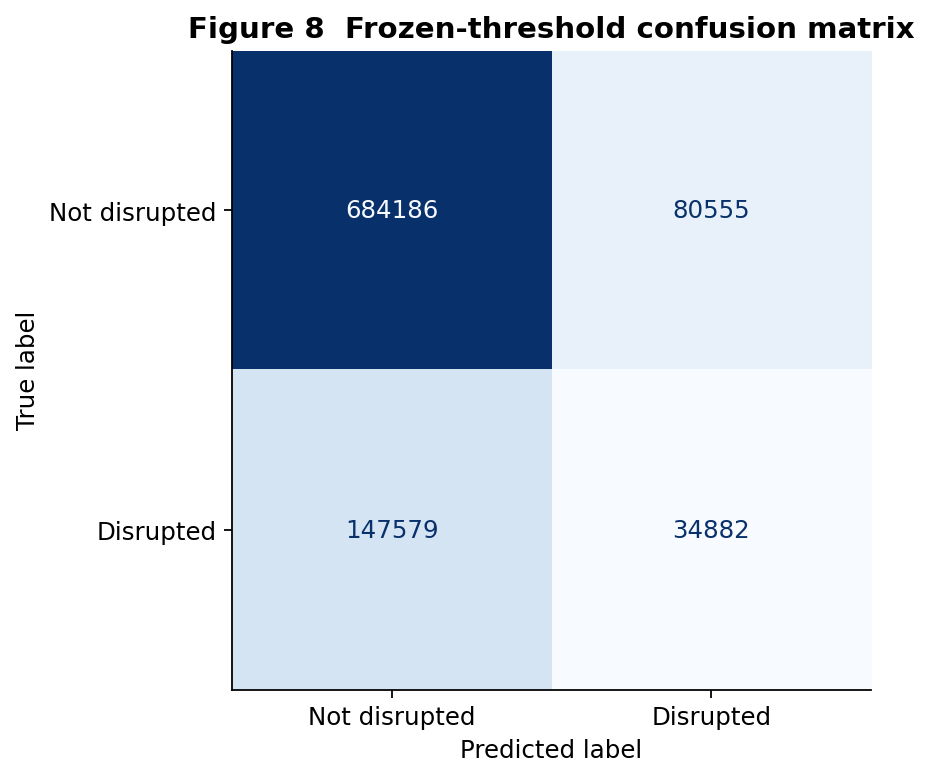

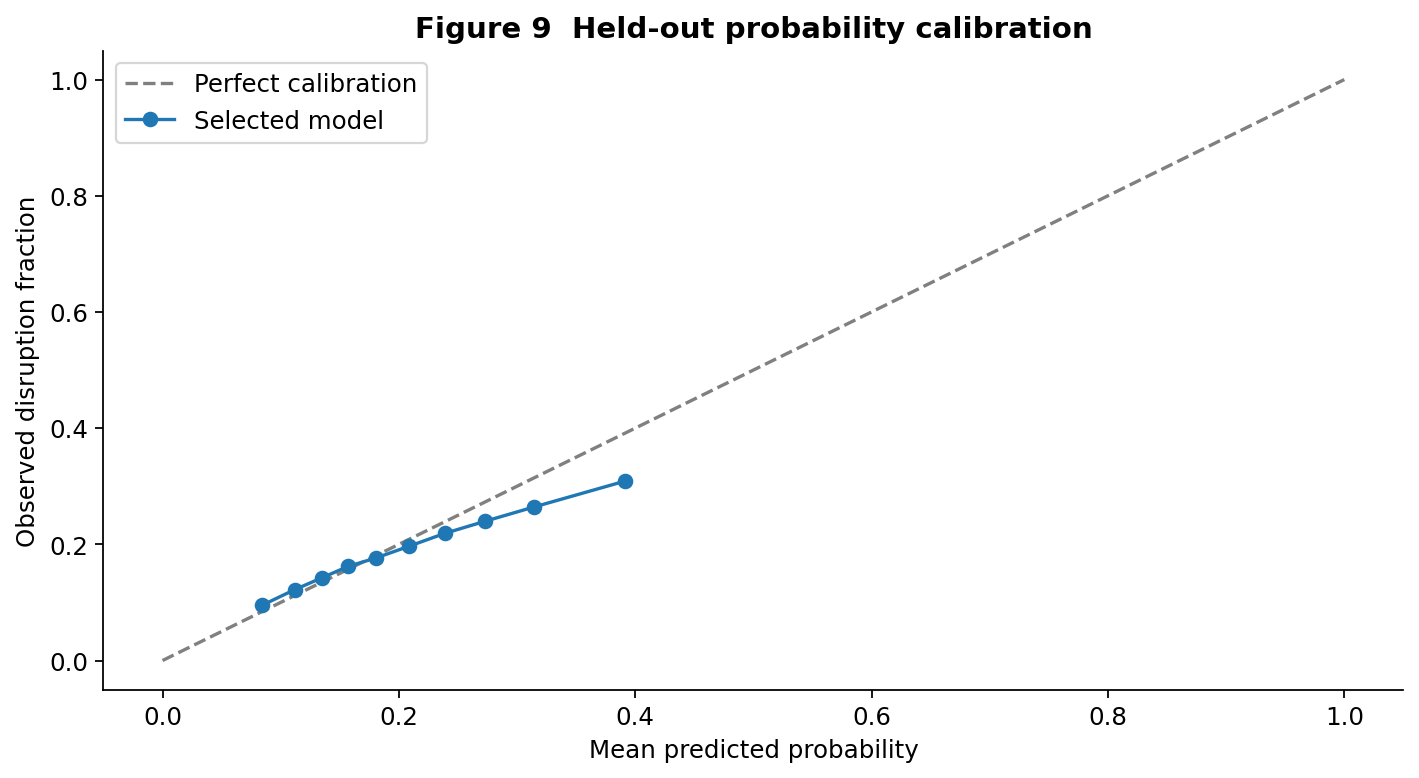

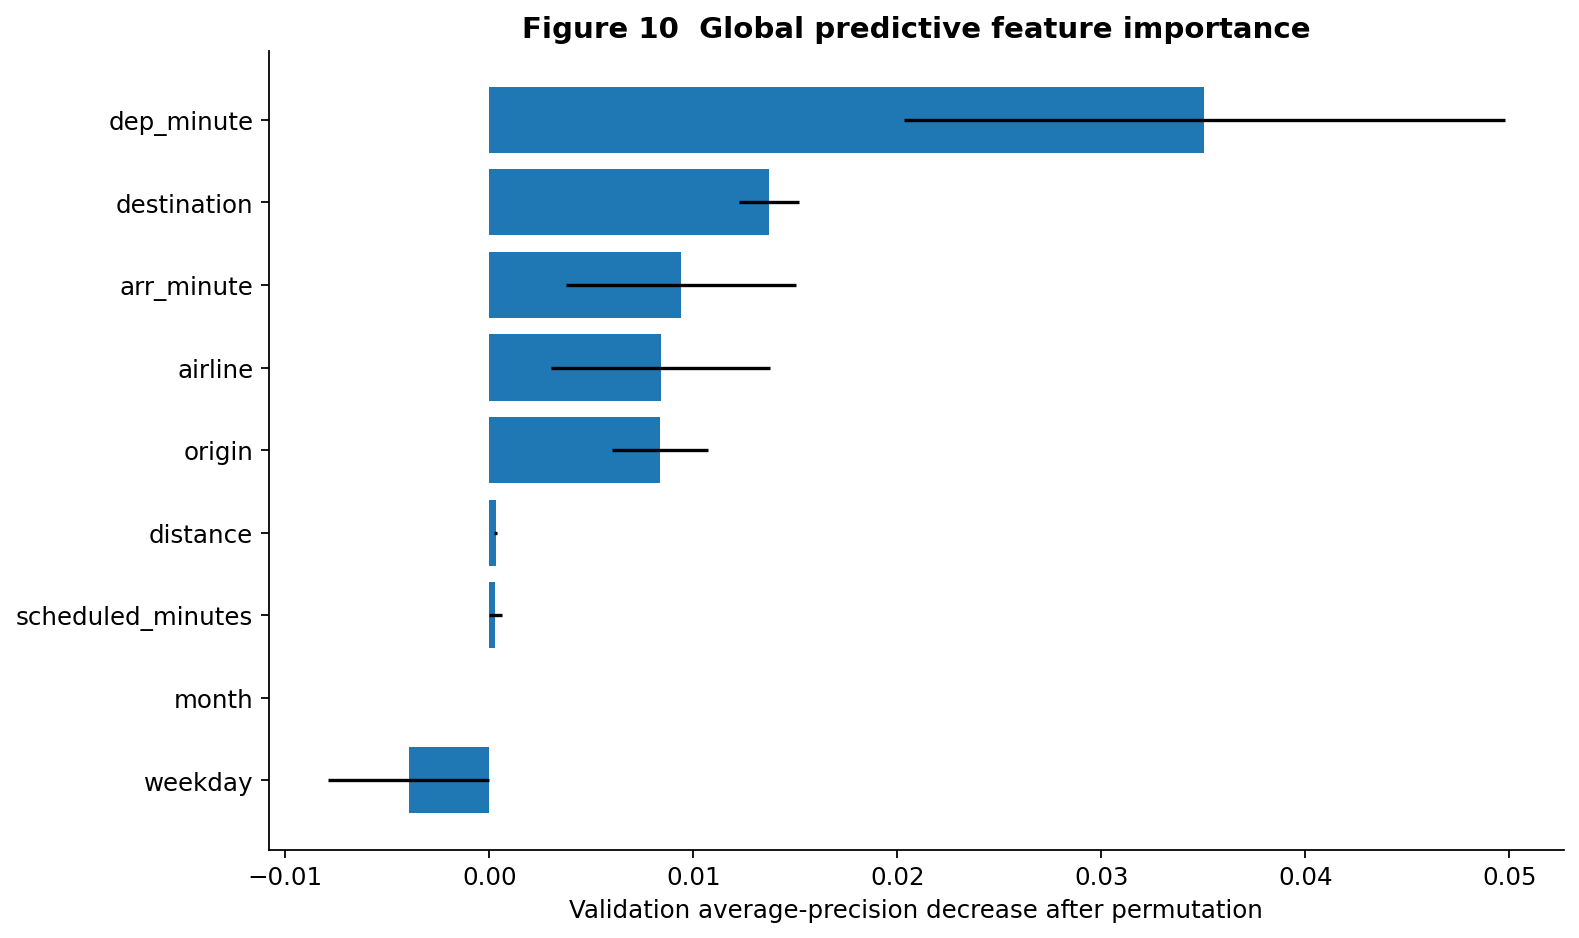

In [3]:
if not (ROOT / 'reports/figure_captions.json').exists():
    run_stage('build_visuals.py')
from IPython.display import Image, display
for item in json.loads((ROOT / 'reports/figure_captions.json').read_text())[5:]:
    display(Image(filename=str(ROOT / 'reports/figures' / item['filename'])))
    print(item['caption'])

Student analysis prompts: Compare improvement to prevalence, AP to ROC AUC, ranking capacity to a fixed threshold, and observed errors to hypothetical costs. Discuss uncertainty, calibration, weak subgroups and practical limits. Do not claim causal savings.